# Calibrating S
`S` in `conversions.py` converts the wheel-speed readings (`motor.left.speed`, `motor.right.speed`, in Thymio units) to mm/s. Without measurements, everything the robot believes about where it is comes from S × wheel speeds. So S decides how far the robot really drives and how far it really turns.

**Idea:** drive straight along a ruler, log the wheel-speed readings the whole time, and measure the distance actually driven:

$$S = \frac{\text{distance driven [mm]}}{\int \text{mean wheel-speed reading}\;dt\ \text{[units·s]}}$$

This integrates the same readings the demo integrates, including speeding up and stopping. So the timing doesn't need to be exact: only the two ruler readings have to be accurate.

## What you need
- **The 30 cm ruler, taped flat** to the table. Use the same surface the demo runs on, because the tyres' grip affects S.
- **A pointer on the robot:** a small piece of tape on the side of the robot, just above the ruler, with a thin vertical pen line on it. (Or use the robot's flat back edge and hold a card against it when reading.) Use the same pointer for every reading.
- Thymio Suite open with the robot connected, and the `.venv` kernel selected.

## Each run
1. **Place the robot** next to the ruler, about 5 mm away from it, facing along it towards the larger numbers, with the pointer at about 10 mm.
2. The notebook asks for the **start reading**. Type it in mm (e.g. `12.5`) and press Enter.
3. **Lightly tap the forward button (▲)** on the robot. It waits 1 s so your hand is clear, drives about 23 cm straight, and stops by itself.
4. When the notebook says it has stopped, read the pointer and type the **end reading**.
   - Type `x` instead if something went wrong (you bumped it, it slipped, it touched the ruler). The run is discarded and repeated.
   - To abort a run while it's moving, tap the centre button (●).
5. Put the robot back for the next run.

Read to the nearest 0.5 mm, looking straight down so you don't read at an angle (parallax). A 0.5 mm reading error is about 0.2% of S.

The default plan is **6 runs**: speeds of 40, 80 and 120 units, which are roughly the demo's docking, turning and cruising wheel speeds, each twice. Each run is saved to `calibration_runs.csv` as soon as it's done. If you stop (type `q` at a start reading, or interrupt the kernel), rerun the cell and it continues where it left off. Delete the file to start from scratch.

In [1]:
%matplotlib inline

import csv
import math
import time
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import conversions

SPEEDS = [40, 80, 120]   # motor targets [Thymio units]
REPEATS = 2              # runs per speed (interleaved, so slow drifts like battery level average out)
RUN_DIST = 230.0         # distance per run [mm], estimated with the current S (fits on the 30 cm ruler)
START_DELAY = 1.0        # wait after the button press so your hand is clear [s]
TAIL = 1.0               # keep logging after the stop command until the wheels are still [s]
DT = 0.02                # logging period [s]
CSV_PATH = Path("calibration_runs.csv")
S_CURRENT = conversions.S

## Connect
This also loads an empty program on the Thymio, so its built-in behaviours don't react to the button presses. They come back when you switch the robot off and on.

In [2]:
if "node" not in globals():
    from tdmclient import ClientAsync
    client = ClientAsync()
    node = await client.wait_for_node()
    await node.lock()
    error = await node.compile("")
    if error is None:
        await node.run()
    else:
        print("Couldn't load an empty program, so the built-in behaviours may react to the buttons:", error)
await node.wait_for_variables({"motor.left.speed", "motor.right.speed", "button.forward", "button.center"})
print("Connected to the Thymio and locked it")

Connected to the Thymio and locked it


In [3]:
FIELDS = ["time", "target", "duration", "integral", "integral_left", "integral_right", "mean_reading",
          "start_mm", "end_mm", "distance_mm", "S"]


def motors(left, right):
    return {"motor.left.target": [int(left)], "motor.right.target": [int(right)]}


def read_speeds():
    return node["motor.left.speed"], node["motor.right.speed"]


async def wait_for_press(button):
    while node[button]:          # wait until it's released (e.g. from an earlier press)
        await client.sleep(DT)
    while not node[button]:
        await client.sleep(DT)


async def drive_and_log(target, duration):
    """Drive straight at `target` for `duration` s and log (t, left, right) readings until the wheels have
    stopped. Returns the samples and whether the run was aborted with the centre button."""
    samples, aborted = [], False
    t0 = time.monotonic()
    samples.append((0.0, *read_speeds()))
    node.send_set_variables(motors(target, target))
    try:
        while (t := time.monotonic() - t0) < duration:
            samples.append((t, *read_speeds()))
            if node["button.center"]:
                aborted = True
                break
            await client.sleep(DT)
    finally:
        node.send_set_variables(motors(0, 0))
    t_stop = time.monotonic() - t0
    while (t := time.monotonic() - t0) < t_stop + TAIL:
        samples.append((t, *read_speeds()))
        await client.sleep(DT)
    return np.array(samples, dtype=float), aborted


def ask_mm(prompt):
    """A ruler reading in mm, or None if the answer was x or q."""
    while True:
        answer = input(prompt).strip().replace(",", ".")
        if answer.lower() in ("x", "q"):
            return None
        try:
            return float(answer)
        except ValueError:
            print(f"'{answer}' isn't a number. Type the reading in mm (e.g. 12.5), or x / q.")


def load_runs():
    if not CSV_PATH.exists():
        return []
    with CSV_PATH.open(newline="") as f:
        return [{k: (v if k == "time" else float(v)) for k, v in row.items()} for row in csv.DictReader(f)]


def save_run(row):
    new_file = not CSV_PATH.exists()
    with CSV_PATH.open("a", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=FIELDS)
        if new_file:
            writer.writeheader()
        writer.writerow(row)


async def run_plan():
    plan = [speed for _ in range(REPEATS) for speed in SPEEDS]
    done = len(load_runs())
    if done >= len(plan):
        print(f"All {len(plan)} planned runs are already in {CSV_PATH}. Increase REPEATS for more, or delete the file to start over.")
        return
    if done:
        print(f"{done} runs already saved in {CSV_PATH}: continuing with run {done + 1}.")

    i = done
    while i < len(plan):
        target = plan[i]
        duration = RUN_DIST / (S_CURRENT * target)
        print(f"\n--- Run {i + 1}/{len(plan)}: speed {target} units, about {duration:.1f} s ---")
        start = ask_mm("Start reading [mm] (q to stop for now): ")
        if start is None:
            print("Stopped. The runs so far are saved; rerun this cell to continue.")
            return
        print("Tap the forward button (▲) on the Thymio to start.")
        await wait_for_press("button.forward")
        await client.sleep(START_DELAY)
        samples, aborted = await drive_and_log(target, duration)
        if aborted:
            print("Aborted with the centre button. Repeating this run.")
            continue
        print("Stopped.")
        while True:
            end = ask_mm("End reading [mm] (x to discard and repeat): ")
            if end is None or end > start:
                break
            print("The end reading must be larger than the start reading.")
        if end is None:
            print("Discarded. Repeating this run.")
            continue

        t, left, right = samples.T
        integral, integral_left, integral_right = (np.trapezoid((left + right) / 2, t),
                                                   np.trapezoid(left, t), np.trapezoid(right, t))
        steady = (t > 0.5) & (t < duration)  # after speeding up, before the stop command
        mean_reading = float(np.mean((left[steady] + right[steady]) / 2)) if steady.any() else float("nan")
        S_run = (end - start) / integral
        save_run(dict(time=datetime.now().isoformat(timespec="seconds"), target=target, duration=duration,
                      integral=integral, integral_left=integral_left, integral_right=integral_right,
                      mean_reading=mean_reading, start_mm=start, end_mm=end, distance_mm=end - start, S=S_run))
        print(f"Distance {end - start:.1f} mm, integrated readings {integral:.1f} units·s  ->  S = {S_run:.4f} mm/s per unit")
        if abs(S_run / S_CURRENT - 1) > 0.25:
            print("That's more than 25% off the current S. Double-check the readings, and type x next time if a run looks wrong.")
        i += 1
    print("\nAll runs done. Run the cells below for the result.")

## Run the calibration
Follow the prompts. The input box appears at the top of the window in VS Code, and below the cell in Jupyter.

In [4]:
await run_plan()


--- Run 1/6: speed 40 units, about 11.5 s ---
Tap the forward button (▲) on the Thymio to start.
Stopped.
Distance 156.0 mm, integrated readings 447.9 units·s  ->  S = 0.3483 mm/s per unit
That's more than 25% off the current S. Double-check the readings, and type x next time if a run looks wrong.

--- Run 2/6: speed 80 units, about 5.7 s ---
Tap the forward button (▲) on the Thymio to start.
Stopped.
Distance 146.0 mm, integrated readings 453.8 units·s  ->  S = 0.3217 mm/s per unit
That's more than 25% off the current S. Double-check the readings, and type x next time if a run looks wrong.

--- Run 3/6: speed 120 units, about 3.8 s ---
Tap the forward button (▲) on the Thymio to start.
Stopped.
Distance 146.0 mm, integrated readings 458.2 units·s  ->  S = 0.3186 mm/s per unit
That's more than 25% off the current S. Double-check the readings, and type x next time if a run looks wrong.

--- Run 4/6: speed 40 units, about 11.5 s ---
Tap the forward button (▲) on the Thymio to start.
Sto

## Result
S is the least-squares fit of *distance = S × integrated readings* over all saved runs. The ± is the standard error over the runs. If the speeds give clearly different values, the printout says so.

run  speed  reading/target  distance [mm]  integral [units·s]        S
  1     40           0.989          156.0               447.9   0.3483
  2     80           1.004          146.0               453.8   0.3217
  3    120           0.998          146.0               458.2   0.3186
  4     40           0.991          153.0               450.9   0.3393
  5     80           0.991          150.0               449.9   0.3334
  6    120           0.984          142.0               448.2   0.3169

speed   40: S = 0.3438  (2 runs)
speed   80: S = 0.3276  (2 runs)
speed  120: S = 0.3177  (2 runs)


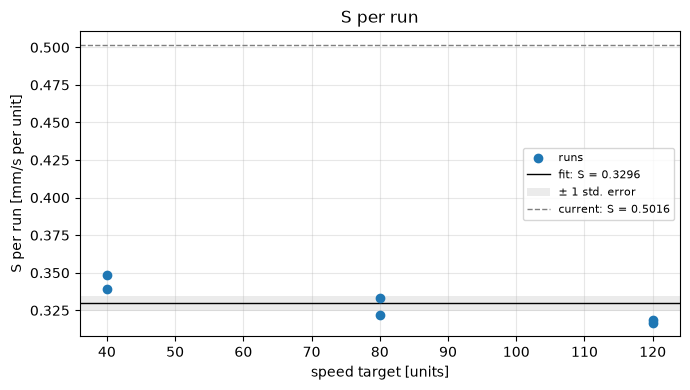


S = 0.3296 mm/s per unit   (± 0.0052, 6 runs)
The current value in conversions.py is 0.5016, so this one is -34.3%.
To use it, set this in conversions.py:

    S = 0.329605


In [5]:
runs = load_runs()
if not runs:
    print(f"No runs in {CSV_PATH} yet.")
else:
    target = np.array([r["target"] for r in runs])
    integral = np.array([r["integral"] for r in runs])
    dist = np.array([r["distance_mm"] for r in runs])
    S_runs = dist / integral
    n = len(runs)
    S_fit = float(np.sum(dist * integral) / np.sum(integral**2))
    sem = float(S_runs.std(ddof=1) / math.sqrt(n)) if n > 1 else float("nan")

    print(f"{'run':>3} {'speed':>6} {'reading/target':>15} {'distance [mm]':>14} {'integral [units·s]':>19} {'S':>8}")
    for k, r in enumerate(runs):
        print(f"{k + 1:>3} {r['target']:>6.0f} {r['mean_reading'] / r['target']:>15.3f} {r['distance_mm']:>14.1f} "
              f"{r['integral']:>19.1f} {S_runs[k]:>8.4f}")
    print()
    speeds = sorted(set(target))
    for s in speeds:
        m = target == s
        print(f"speed {s:>4.0f}: S = {S_runs[m].mean():.4f}  ({m.sum()} runs)")
    if n > 2 and len(speeds) > 1:
        spread = max(abs(S_runs[target == s].mean() - S_fit) for s in speeds)
        if spread > max(3 * sem, 0.01 * S_fit):
            print("-> S depends on speed noticeably. Use the value for the speed the robot spends most time at, "
                  "or a speed-dependent conversion.")

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.scatter(target, S_runs, color="#1f77b4", zorder=3, label="runs")
    ax.axhline(S_fit, color="k", lw=1, label=f"fit: S = {S_fit:.4f}")
    if n > 1:
        ax.axhspan(S_fit - sem, S_fit + sem, color="k", alpha=0.08, lw=0, label="± 1 std. error")
    ax.axhline(S_CURRENT, color="0.5", ls="--", lw=1, label=f"current: S = {S_CURRENT:.4f}")
    ax.set_xlabel("speed target [units]")
    ax.set_ylabel("S per run [mm/s per unit]")
    ax.set_title("S per run")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

    print(f"\nS = {S_fit:.4f} mm/s per unit   (± {sem:.4f}, {n} runs)")
    print(f"The current value in conversions.py is {S_CURRENT:.4f}, so this one is {100 * (S_fit / S_CURRENT - 1):+.1f}%.")
    print(f"To use it, set this in conversions.py:\n\n    S = {S_fit:.6f}")

## Stop and unlock

In [6]:
if "node" in globals():
    node.send_set_variables(motors(0, 0))
    await node.unlock()
    del node
    print("Thymio stopped and unlocked")

Thymio stopped and unlocked
